In [31]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/house-prices-advanced-regression-techniques/sample_submission.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/data_description.txt
/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv
/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv



**ЧАСТЬ I — ЗНАКОМСТВО И ПОДГОТОВКА К ИССЛЕДОВАНИЮ**

Проект: House Prices — Advanced Regression Techniques
Платформа: Kaggle
Тип задачи: Регрессия
В этой части у нас три этапа:
1. **Знакомство с задачей — что предсказываем, какие данные доступны и как оценивается результат.**
2. **Загрузка данных — изучаем структуру датасета, размеры и типы признаков.**
3. **Разделение данных — Train / Validation и подготовка к кросс-валидации.**


In [32]:
import pandas as pd
import numpy as np

train = pd.read_csv(
    '/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv'
)

test = pd.read_csv(
    '/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv'
)

# загружаем данные

In [33]:
print('Train:', train.shape)
print('Test:', test.shape)

train.head()

Train: (1460, 81)
Test: (1459, 80)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [34]:
numeric_cols = [
    'LotFrontage', 'LotArea',
    'YearBuilt', 'YearRemodAdd',
    'MasVnrArea',
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
    'TotalBsmtSF',
    '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
    'GrLivArea',
    'BsmtFullBath', 'BsmtHalfBath',
    'FullBath', 'HalfBath',
    'BedroomAbvGr', 'KitchenAbvGr',
    'TotRmsAbvGrd',
    'Fireplaces',
    'GarageYrBlt', 'GarageCars', 'GarageArea',
    'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
    '3SsnPorch', 'ScreenPorch', 'PoolArea',
    'MiscVal', 'YrSold'
]

nominal_cols = [
    'MSSubClass', 'MSZoning', 'Street', 'Alley',
    'LandContour', 'LotConfig',
    'Neighborhood', 'Condition1', 'Condition2',
    'BldgType', 'HouseStyle',
    'RoofStyle', 'RoofMatl',
    'Exterior1st', 'Exterior2nd', 'MasVnrType',
    'Foundation',
    'Heating', 'CentralAir', 'Electrical',
    'GarageType',
    'Fence', 'MiscFeature',
    'MoSold', 'SaleType', 'SaleCondition'
]

ordinal_cols = [
    'LotShape', 'Utilities', 'LandSlope',
    'OverallQual', 'OverallCond',
    'ExterQual', 'ExterCond',
    'BsmtQual', 'BsmtCond', 'BsmtExposure',
    'BsmtFinType1', 'BsmtFinType2',
    'HeatingQC', 'KitchenQual',
    'Functional', 'FireplaceQu',
    'GarageFinish', 'GarageQual', 'GarageCond',
    'PavedDrive', 'PoolQC'
]

In [35]:
all_cols = numeric_cols + nominal_cols + ordinal_cols

feature_cols = set(train.columns) - {'Id', 'SalePrice'}

missing_cols = feature_cols - set(all_cols)
extra_cols = set(all_cols) - feature_cols

print('Numeric:', len(numeric_cols))
print('Nominal:', len(nominal_cols))
print('Ordinal:', len(ordinal_cols))
print('Всего:', len(all_cols))

print('Пропущенные:', missing_cols)
print('Лишние:', extra_cols)
print('Повторы:', len(all_cols) - len(set(all_cols)))

Numeric: 32
Nominal: 26
Ordinal: 21
Всего: 79
Пропущенные: set()
Лишние: set()
Повторы: 0


In [36]:
from sklearn.model_selection import train_test_split

X = train.drop(columns=['Id', 'SalePrice'])
y = train['SalePrice']

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state= 42
)

In [37]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (1168, 79)
X_val: (292, 79)
y_train: (1168,)
y_val: (292,)


**Часть II**

4. EDA.
5. Pipeline предобработки.

In [38]:
train['SalePrice'].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

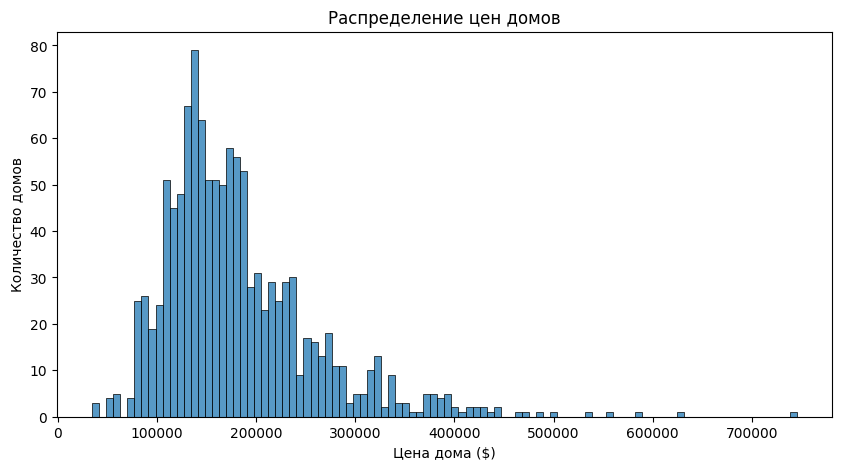

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))

sns.histplot(y_train, bins=100)

plt.title('Распределение цен домов')
plt.xlabel('Цена дома ($)')
plt.ylabel('Количество домов')

plt.show()

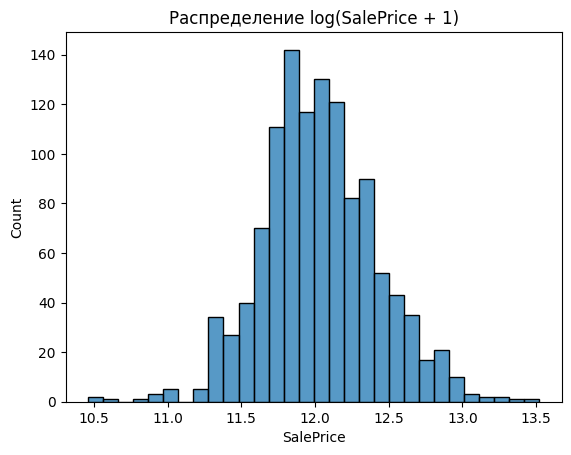

In [40]:
sns.histplot(np.log1p(y_train), bins=30)
plt.title('Распределение log(SalePrice + 1)')
plt.show()

### 4.1. Анализ целевой переменной SalePrice

**Основные статистики (исходный train.csv):**
- Количество объектов: 1460
- Средняя стоимость: $180 921
- Медианная стоимость: $163 000
- Стандартное отклонение: $79 443
- Минимальная стоимость: $34 900
- Максимальная стоимость: $755 000

**Наблюдения:**
1. Распределение цен имеет выраженную правостороннюю асимметрию.
2. Средняя стоимость выше медианной, что согласуется с наличием длинного правого хвоста.
3. В данных встречаются редкие дорогие дома. Пока нет оснований считать их ошибками и удалять.
4. После преобразования `np.log1p(SalePrice)` распределение становится более симметричным и визуально напоминает нормальное.

**Гипотеза для моделирования:**

Обучение модели на логарифмированной целевой переменной может быть полезным с учётом распределения цен и метрики соревнования.

**Решение:**

Не удалять дорогие дома на данном этапе. Сохранить исходный `SalePrice` и проверить целесообразность логарифмирования при построении моделей.

In [41]:
missing = X_train.isna().sum()

missing = missing[missing > 0]
missing = missing.sort_values(ascending=False)
print(missing)

PoolQC          1162
MiscFeature     1122
Alley           1094
Fence            935
MasVnrType       683
FireplaceQu      547
LotFrontage      217
GarageType        64
GarageYrBlt       64
GarageFinish      64
GarageQual        64
GarageCond        64
BsmtCond          28
BsmtFinType1      28
BsmtExposure      28
BsmtQual          28
BsmtFinType2      28
MasVnrArea         6
Electrical         1
dtype: int64


In [42]:
X_train.loc[X_train['PoolQC'].isna(), 'PoolArea'].value_counts()

PoolArea
0    1162
Name: count, dtype: int64

In [43]:
X_train.loc[X_train['GarageType'].isna(), 'GarageArea'].value_counts()

GarageArea
0    64
Name: count, dtype: int64

In [44]:
X_train['LotFrontage'].describe()

count    951.000000
mean      70.343849
std       24.897021
min       21.000000
25%       59.000000
50%       70.000000
75%       80.000000
max      313.000000
Name: LotFrontage, dtype: float64

### 4.3. Анализ пропущенных значений

**Обучающая выборка:** 1168 объектов, 79 признаков.

Пропущенные значения обнаружены в 19 признаках.

**Основные наблюдения:**

1. `PoolQC`: 1162 пропуска (99,5%). Проверка `PoolArea` показала, что у всех этих домов площадь бассейна равна нулю. Пропуски соответствуют отсутствию бассейна.
2. `GarageType`: 64 пропуска (5,5%). Проверка `GarageArea` показала отсутствие гаража у этих домов.
3. `LotFrontage`: 217 пропусков (18,6%). Среднее известных значений — 70,34, медиана — 70, максимум — 313. Есть значения, существенно превышающие верхний квартиль (80).
4. Другие признаки, связанные с отсутствующими объектами (`Alley`, `Fence`, `FireplaceQu`, характеристики подвала и гаража), требуют соответствующей обработки. Их пропуски пока не проверены по отдельности.

**Предварительные решения для предобработки:**

- Для `PoolQC` и `GarageType` использовать отдельную категорию отсутствия объекта.
- Для `LotFrontage` попробовать заполнение медианой.
- Для остальных признаков определить стратегию с учётом их смысла и типа данных.
- Все параметры заполнения вычислять внутри обучающих частей кросс-валидации с помощью `SimpleImputer` и `Pipeline`, чтобы избежать утечки данных.

**Вывод:** пропуски имеют разную природу. Не следует применять одну стратегию заполнения ко всем признакам без учёта их смысла.

In [45]:
X_train['GrLivArea'].corr(y_train)

np.float64(0.6956519144967794)

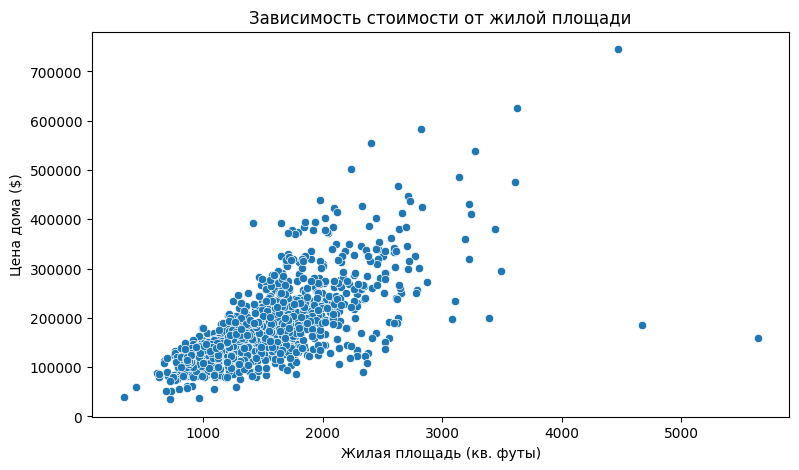

In [46]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    x=X_train['GrLivArea'],
    y=y_train
)

plt.xlabel('Жилая площадь (кв. футы)')
plt.ylabel('Цена дома ($)')
plt.title('Зависимость стоимости от жилой площади')

plt.show()

In [47]:
X_train[numeric_cols].corrwith(y_train).sort_values(ascending=False)

GrLivArea        0.695652
GarageCars       0.640991
GarageArea       0.624139
TotalBsmtSF      0.597766
1stFlrSF         0.587883
FullBath         0.552546
TotRmsAbvGrd     0.520388
YearBuilt        0.516501
YearRemodAdd     0.508593
GarageYrBlt      0.480351
MasVnrArea       0.459123
Fireplaces       0.457549
BsmtFinSF1       0.359460
LotFrontage      0.330066
WoodDeckSF       0.329843
2ndFlrSF         0.314030
OpenPorchSF      0.299969
HalfBath         0.280481
LotArea          0.266204
BsmtFullBath     0.226346
BsmtUnfSF        0.222487
BedroomAbvGr     0.156211
ScreenPorch      0.119172
PoolArea         0.115630
3SsnPorch        0.051532
BsmtFinSF2      -0.005731
YrSold          -0.009099
LowQualFinSF    -0.011189
MiscVal         -0.020179
BsmtHalfBath    -0.048346
KitchenAbvGr    -0.142785
EnclosedPorch   -0.149532
dtype: float64

In [48]:
X_train['GarageCars'].corr(X_train['GarageArea'])

np.float64(0.8825495083743986)

### 4.4. Анализ числовых признаков

**Основные наблюдения:**

1. Наиболее высокая положительная корреляция с `SalePrice` обнаружена у `GrLivArea` (0.696), `GarageCars` (0.641), `GarageArea` (0.624), `TotalBsmtSF` (0.598).
2. Scatterplot `GrLivArea` и `SalePrice` показывает выраженную положительную зависимость. При увеличении площади наблюдается увеличение разброса цен.
3. Обнаружены необычные дома с большой жилой площадью и относительно низкой стоимостью. Пока не удаляем их.
4. `GarageCars` и `GarageArea` сильно коррелируют между собой (0.883). Это потенциальный источник мультиколлинеарности для линейных моделей.
5. Некоторые числовые признаки имеют слабую корреляцию с ценой, но это не доказывает их бесполезность.

**Предварительные решения:**

- Сохранить все числовые признаки для первых экспериментов.
- Использовать Ridge как одну из базовых моделей.
- Не удалять признаки и наблюдения исключительно на основании корреляций.
- Проверять полезность признаков и качество предсказаний на кросс-валидации.

In [49]:
X_train['Neighborhood'].nunique()

25

In [50]:
X_train['Neighborhood'].value_counts()

Neighborhood
NAmes      181
CollgCr    115
OldTown     91
Edwards     87
Somerst     69
NWAmes      66
Gilbert     65
NridgHt     61
Sawyer      58
BrkSide     45
Crawfor     44
SawyerW     44
Mitchel     40
NoRidge     33
Timber      28
IDOTRR      26
SWISU       21
StoneBr     20
ClearCr     19
Blmngtn     15
BrDale      13
MeadowV     10
Veenker      9
NPkVill      7
Blueste      1
Name: count, dtype: int64

In [51]:
neighborhood_stats = (
    X_train.join(y_train)
    .groupby('Neighborhood')['SalePrice']
    .agg(['count', 'median'])
    .sort_values('median', ascending=False)
)

neighborhood_stats

,count,median
Neighborhood,,
NridgHt,61,314813.0
NoRidge,33,290000.0
StoneBr,20,282000.0
Veenker,9,245500.0
Somerst,69,226700.0
Timber,28,226250.0
ClearCr,19,211000.0
Crawfor,44,208550.0
CollgCr,115,200500.0


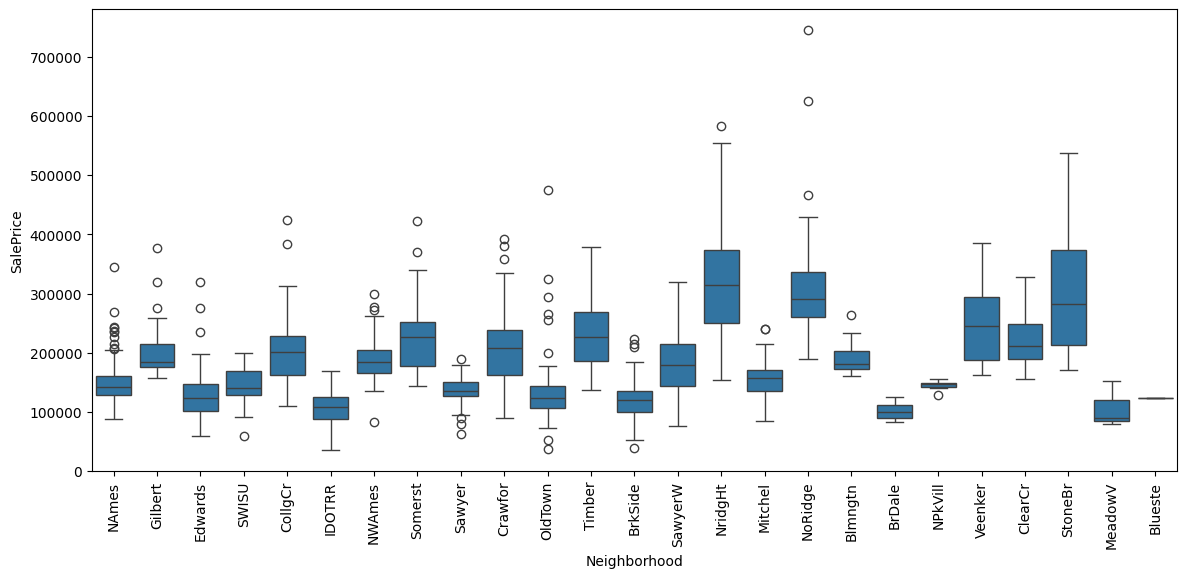

In [52]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=X_train.join(y_train),
    x='Neighborhood',
    y='SalePrice'
)

plt.xticks(rotation=90)
plt.show()

### 4.5. Анализ категориальных признаков — Neighborhood

**Наблюдения:**

- В обучающей выборке представлено 25 районов, количество домов в которых существенно различается.
- Наиболее представленный район — `NAmes` (181 дом), наименее представленный — `Blueste` (1 дом).
- Медианная стоимость домов заметно отличается между районами: например, `NridgHt` — $314 813, `NAmes` — $142 000, `MeadowV` — $89 500.
- Boxplot показывает различия не только в медианной стоимости, но и в разбросе цен внутри районов.
- В некоторых районах наблюдаются выбросы. Пока не удаляем их, поскольку высокая или низкая стоимость может быть обусловлена реальными характеристиками недвижимости.
- Для районов с малым количеством наблюдений статистические оценки менее надёжны.

**Предварительный вывод:** `Neighborhood` потенциально является важным категориальным признаком для предсказания `SalePrice`. Сохраняем его для дальнейшего моделирования.

In [53]:
X_train['OverallQual'].corr(y_train)

np.float64(0.7855547508295232)

In [54]:
X_train.join(y_train).groupby('OverallQual')['SalePrice'].median()

OverallQual
1      50150.0
2      60000.0
3      86250.0
4     108250.0
5     133850.0
6     161750.0
7     200000.0
8     268000.0
9     343821.5
10    402861.0
Name: SalePrice, dtype: float64

### 4.5.1. Анализ OverallQual

- `OverallQual` — порядковый признак, характеризующий общее качество дома по шкале от 1 до 10.
- Обнаружена сильная положительная корреляция с `SalePrice`: **0.786**.
- Медианная стоимость последовательно увеличивается с ростом оценки качества: от $50 150 при оценке 1 до $402 861 при оценке 10.
- Разница между медианными ценами соседних категорий неодинакова, что указывает на возможную нелинейность зависимости.
- Более высокая оценка качества не гарантирует более высокую стоимость каждого конкретного дома.

**Вывод:** `OverallQual` — один из наиболее перспективных признаков для предсказания стоимости недвижимости. Сохраняем его для моделирования.

In [55]:
X_train['OverallQual'].value_counts().sort_index()

OverallQual
1       2
2       1
3      16
4      88
5     308
6     311
7     258
8     135
9      36
10     13
Name: count, dtype: int64

**Распределение оценок качества:**

- Большинство домов имеют оценку `OverallQual` от 5 до 7 (877 из 1168 наблюдений).
- Крайние оценки встречаются редко: качество 1 — 2 дома, качество 2 — 1 дом, качество 10 — 13 домов.
- Медианные цены редких категорий менее устойчивы из-за малого количества наблюдений.

**Вывод:** положительная связь между качеством дома и стоимостью выражена достаточно отчётливо, но интерпретировать крайние категории нужно осторожно.

In [56]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

# 1. Числовые признаки
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# 2. Номинальные признаки
nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# 3. Порядковые признаки
# Пока используем упрощённое кодирование.
# Позже уточним порядок категорий.
ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('encoder', OrdinalEncoder(
        handle_unknown='use_encoded_value',
        unknown_value=-1
    ))
])

# 4. Объединяем три ветки
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_cols),
    ('nom', nominal_pipeline, nominal_cols),
    ('ord', ordinal_pipeline, ordinal_cols)
])

In [57]:
from sklearn.linear_model import Ridge

ridge_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge(alpha=10.0))
])

In [58]:
ridge_model.fit(X_train, np.log1p(y_train))

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LotFrontage', 'LotArea',
                                                   'YearBuilt', 'YearRemodAdd',
                                                   'MasVnrArea', 'BsmtFinSF1',
                                                   'BsmtFinSF2', 'BsmtUnfSF',
                                                   'TotalBsmtSF', '1stFlrSF',
                                                   '2ndFlrSF', 'LowQualFinSF',
                                                   'GrLivArea', 'BsmtFullBath',
                                                   'BsmtHa...
                                                                   OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                  unknown_value=-1))]),
                                                  ['LotShape', 'Utilities',
                                                   'LandSlope', 'OverallQual',
                                                   'OverallCond', 'ExterQual',
                                                   'ExterCond', 'BsmtQual',
                                                   'BsmtCond', 'BsmtExposure',
                                                   'BsmtFinType1',
                                                   'BsmtFinType2', 'HeatingQC',
                                                   'KitchenQual', 'Functional',
                                                   'FireplaceQu',
                                                   'GarageFinish', 'GarageQual',
                                                   'GarageCond', 'PavedDrive',
                                                   'PoolQC'])])),
                ('model', Ridge(alpha=10.0))])

In [59]:
from sklearn.metrics import mean_squared_log_error

# Предсказания в логарифмической шкале
pred_log = ridge_model.predict(X_val)

# Возвращаем цены в доллары
pred_prices = np.expm1(pred_log)

# Считаем RMSLE
rmsle = np.sqrt(
    mean_squared_log_error(y_val, pred_prices)
)

print(f"RMSLE: {rmsle:.5f}")

RMSLE: 0.13957


In [60]:
from sklearn.dummy import DummyRegressor

dummy = DummyRegressor(strategy='mean')

dummy.fit(X_train, np.log1p(y_train))

dummy_pred_log = dummy.predict(X_val)
dummy_pred_prices = np.expm1(dummy_pred_log)

dummy_rmsle = np.sqrt(
    mean_squared_log_error(y_val, dummy_pred_prices)
)

print(f"Dummy RMSLE: {dummy_rmsle:.5f}")
print(f"Ridge RMSLE: {rmsle:.5f}")

Dummy RMSLE: 0.43324
Ridge RMSLE: 0.13957


### 6. Первый эксперимент: DummyRegressor vs Ridge

**Условия эксперимента:**

- Обучающая выборка: 1168 домов.
- Валидационная выборка: 292 дома.
- Целевая переменная преобразована через `np.log1p(SalePrice)`.
- Для Ridge использована предварительная обработка через `Pipeline` и `ColumnTransformer`.
- Ridge: `alpha=10.0`.
- Метрика качества: RMSLE (меньше — лучше).

| Модель | Validation RMSLE |
|---|---:|
| DummyRegressor (mean) | 0.43324 |
| Ridge | 0.13957 |

**Выводы:**

1. Ridge снизила RMSLE примерно на 67,8% относительно DummyRegressor.
2. Характеристики домов содержат полезную информацию для предсказания стоимости.
3. Результат пока получен на одном разбиении данных и требует проверки кросс-валидацией.
4. Текущая предобработка порядковых признаков упрощена; её необходимо уточнить перед окончательным выбором модели.

**Следующий шаг:** оценить устойчивость Ridge с помощью 5-fold cross-validation.

In [61]:
from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

KFold(n_splits=5, random_state=42, shuffle=True)


In [62]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    ridge_model,
    X_train,
    np.log1p(y_train),
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

rmsle_scores = - cv_scores

print("Ошибки по 5 разбиениям:", rmsle_scores)
print(f"Средняя ошибка: {rmsle_scores.mean():.5f}")
print(f"Стандартное отклонение: {rmsle_scores.std():.5f}")

Ошибки по 5 разбиениям: [0.1387876  0.13484197 0.19728359 0.11948048 0.1218613 ]
Средняя ошибка: 0.14245
Стандартное отклонение: 0.02839


### 7. Cross-validation: Ridge

Для проверки устойчивости Ridge использована 5-fold кросс-валидация на обучающей выборке (1168 домов).

На каждом разбиении заново обучается весь Pipeline, включая предобработку признаков.

**Результаты:**

- Fold 1: 0.13879
- Fold 2: 0.13484
- Fold 3: 0.19728
- Fold 4: 0.11948
- Fold 5: 0.12186

**Средняя RMSE в шкале log1p:** 0.14245  
**Стандартное отклонение:** 0.02839

**Вывод:** Средняя ошибка кросс-валидации близка к результату на отдельной валидационной выборке (RMSLE = 0.13957). Однако третий fold показывает существенно более высокую ошибку. Это указывает на некоторую нестабильность качества и требует дальнейшего анализа.

Следующий шаг — сравнить Ridge с другими алгоритмами при одинаковой схеме кросс-валидации.


In [63]:
from sklearn.ensemble import RandomForestRegressor

forest_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [64]:
forest_cv_scores = cross_val_score(
    forest_model,
    X_train,
    np.log1p(y_train),
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

forest_rmse_scores = -forest_cv_scores

print("Ошибки по 5 разбиениям:", forest_rmse_scores)
print(f"Средняя ошибка: {forest_rmse_scores.mean():.5f}")
print(f"Стандартное отклонение: {forest_rmse_scores.std():.5f}")

Ошибки по 5 разбиениям: [0.15000206 0.15329577 0.17335657 0.13683425 0.12896775]
Средняя ошибка: 0.14849
Стандартное отклонение: 0.01524


### 7.2. Сравнение Ridge и RandomForest

Для сравнения использована 5-fold кросс-валидация с одинаковыми разбиениями и метрикой RMSE в шкале `log1p(SalePrice)`.

| Модель | Mean CV RMSE | Std CV RMSE |
|---|---:|---:|
| Ridge (`alpha=10`) | **0.14245** | 0.02839 |
| RandomForest (`n_estimators=100`) | 0.14849 | **0.01524** |

**Выводы:**

1. Ridge показала меньшую среднюю ошибку, чем RandomForest.
2. RandomForest продемонстрировала меньший разброс ошибки между разбиениями.
3. Третий fold оказался наиболее сложным для обеих моделей.
4. На текущем этапе Ridge остаётся лидером по средней ошибке.
5. Следующий шаг — проверить ещё один алгоритм, после чего перейти к подбору гиперпараметров.

In [65]:
from sklearn.ensemble import GradientBoostingRegressor

boosting_model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

In [66]:
boosting_cv_scores = cross_val_score(
    boosting_model,
    X_train,
    np.log1p(y_train),
    cv=cv,
    scoring='neg_root_mean_squared_error'
)

boosting_rmse_scores = -boosting_cv_scores

print("Ошибки по 5 разбиениям:", boosting_rmse_scores)
print(f"Средняя ошибка: {boosting_rmse_scores.mean():.5f}")
print(f"Стандартное отклонение: {boosting_rmse_scores.std():.5f}")

Ошибки по 5 разбиениям: [0.13168526 0.14570929 0.15746658 0.11604106 0.10633449]
Средняя ошибка: 0.13145
Стандартное отклонение: 0.01870


### 7.3. Сравнение трёх алгоритмов

Для сравнения использована 5-fold кросс-валидация на `X_train` с одинаковыми разбиениями, предобработкой и метрикой RMSE в шкале `log1p(SalePrice)`.

| Модель | Mean CV RMSE | Std CV RMSE |
|---|---:|---:|
| Ridge | 0.14245 | 0.02839 |
| RandomForest | 0.14849 | 0.01524 |
| GradientBoosting | **0.13145** | 0.01870 |

**Выводы:**

1. GradientBoosting показал наименьшую среднюю ошибку среди трёх алгоритмов.
2. RandomForest показал наименьший разброс ошибки между разбиениями.
3. Третий fold оказался самым сложным для всех моделей.
4. GradientBoosting выбран основным кандидатом для дальнейшего подбора гиперпараметров.

**Следующий этап:** подбор гиперпараметров GradientBoosting с помощью `GridSearchCV`.

In [67]:
param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [2, 3, 4]
}

In [68]:
from sklearn.model_selection import GridSearchCV

grid_search = GridSearchCV(
    estimator=boosting_model,
    param_grid=param_grid,
    cv=cv,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

In [69]:
grid_search.fit(X_train, np.log1p(y_train))

print("Лучшие параметры:", grid_search.best_params_)
print(f"Лучшая CV-ошибка: {-grid_search.best_score_:.5f}")

Лучшие параметры: {'model__max_depth': 2, 'model__n_estimators': 200}
Лучшая CV-ошибка: 0.12812


### 8. Подбор гиперпараметров GradientBoosting

Для настройки GradientBoosting использован `GridSearchCV` с 5-fold кросс-валидацией.

Проверены 6 комбинаций:
- `n_estimators`: 100, 200
- `max_depth`: 2, 3, 4

**Лучшие параметры:**
- `n_estimators = 200`
- `max_depth = 2`

**Результаты:**

| Модель | Mean CV RMSE |
|---|---:|
| GradientBoosting до настройки | 0.13145 |
| GradientBoosting после настройки | **0.12812** |

**Вывод:** подбор гиперпараметров снизил среднюю CV-ошибку примерно на 2,5%. Лучшая конфигурация использует больше деревьев меньшей глубины.

Настроенная модель выбрана для финальной оценки на отложенной выборке.

In [70]:
best_model = grid_search.best_estimator_

y_pred_log = best_model.predict(X_val)

y_pred = np.expm1(y_pred_log)

In [71]:
from sklearn.metrics import root_mean_squared_log_error

final_rmsle = root_mean_squared_log_error(
    y_val,
    np.maximum(y_pred, 0)
)

print(f"Final Validation RMSLE: {final_rmsle:.5f}")
print(f"Best CV RMSE (log1p): {-grid_search.best_score_:.5f}")

Final Validation RMSLE: 0.13559
Best CV RMSE (log1p): 0.12812


### 9. Финальная оценка модели

После сравнения Ridge, RandomForest и GradientBoosting была выбрана модель GradientBoostingRegressor.

С помощью GridSearchCV подобраны гиперпараметры:
- `n_estimators = 200`
- `max_depth = 2`
- `learning_rate = 0.1`

**Результаты:**
- Best CV RMSE (log1p): **0.12812**
- Final Validation RMSLE: **0.13559**
- Ridge Validation RMSLE: 0.13957
- Dummy Validation RMSLE: 0.43324

**Вывод:** настроенный GradientBoosting показал лучший результат на отложенной выборке среди проверенных моделей. Финальная ошибка немного выше CV-оценки, но резкого ухудшения качества не наблюдается.

Следующий этап — анализ ошибок предсказания и подготовка итогового решения для Kaggle.

In [72]:
errors_df = pd.DataFrame({
    'Actual': y_val,
    'Predicted': y_pred
})

errors_df['AbsoluteError'] = (
    errors_df['Actual'] - errors_df['Predicted']
).abs()

errors_df['PercentageError'] = (
    errors_df['AbsoluteError'] / errors_df['Actual'] * 100
)

errors_df.sort_values(
    'PercentageError',
    ascending=False
).head(10)

,Actual,Predicted,AbsoluteError,PercentageError
30,40000,91251.570163,51251.570163,128.128925
812,55993,101759.007978,45766.007978,81.735231
1432,64500,104327.932362,39827.932362,61.748732
916,35311,56965.795429,21654.795429,61.325919
588,143000,204847.602848,61847.602848,43.250072
581,253293,360343.397335,107050.397335,42.263465
772,107000,147607.401814,40607.401814,37.950843
1279,68400,94144.407469,25744.407469,37.638023
898,611657,400251.045650,211405.954350,34.562828
874,66500,88502.549473,22002.549473,33.086541


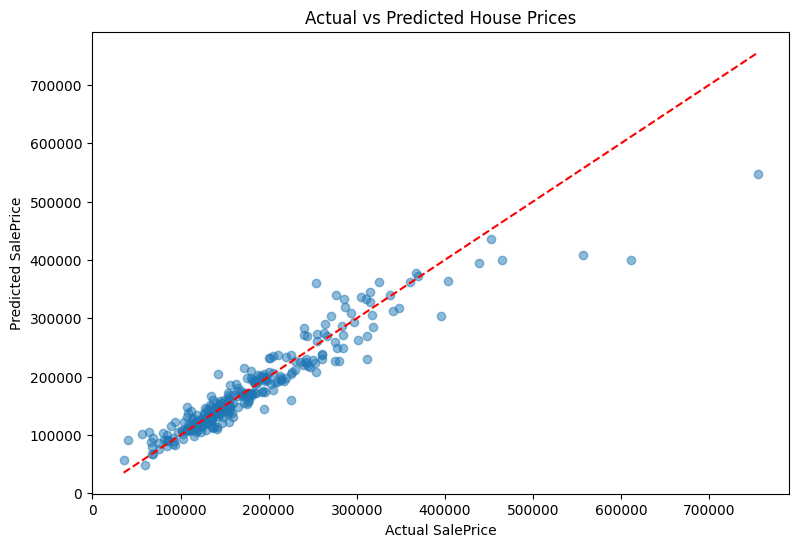

In [73]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_val,
    y_pred,
    alpha=0.5
)

plt.plot(
    [y_val.min(), y_val.max()],
    [y_val.min(), y_val.max()],
    'r--'
)

plt.xlabel('Actual SalePrice')
plt.ylabel('Predicted SalePrice')
plt.title('Actual vs Predicted House Prices')

plt.show()

### 10. Анализ ошибок модели

Для анализа качества GradientBoosting построен график `Actual vs Predicted SalePrice` и рассмотрены 10 объектов с наибольшей относительной ошибкой.

**Наблюдения:**

1. Большинство предсказаний сосредоточено около линии идеального соответствия.
2. Среди объектов с наибольшей относительной ошибкой преобладают дома, стоимость которых модель завысила.
3. На графике наблюдается тенденция к переоценке некоторых дешёвых домов и недооценке дорогих.
4. Возможная причина — сглаживание экстремальных значений стоимости.

**Вывод:** модель демонстрирует хорошее общее качество (Validation RMSLE = 0.13559), но испытывает трудности с отдельными объектами на краях ценового диапазона.

На данном этапе модель принимается как итоговая версия для первой отправки на Kaggle.

In [74]:
from sklearn.base import clone

final_model = clone(grid_search.best_estimator_)

final_model.fit(X, np.log1p(y))

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['LotFrontage', 'LotArea',
                                                   'YearBuilt', 'YearRemodAdd',
                                                   'MasVnrArea', 'BsmtFinSF1',
                                                   'BsmtFinSF2', 'BsmtUnfSF',
                                                   'TotalBsmtSF', '1stFlrSF',
                                                   '2ndFlrSF', 'LowQualFinSF',
                                                   'GrLivArea', 'BsmtFullBath',
                                                   'BsmtHa...
                                                  ['LotShape', 'Utilities',
                                                   'LandSlope', 'OverallQual',
                                                   'OverallCond', 'ExterQual',
                                                   'ExterCond', 'BsmtQual',
                                                   'BsmtCond', 'BsmtExposure',
                                                   'BsmtFinType1',
                                                   'BsmtFinType2', 'HeatingQC',
                                                   'KitchenQual', 'Functional',
                                                   'FireplaceQu',
                                                   'GarageFinish', 'GarageQual',
                                                   'GarageCond', 'PavedDrive',
                                                   'PoolQC'])])),
                ('model',
                 GradientBoostingRegressor(max_depth=2, n_estimators=200,
                                           random_state=42))])

In [75]:
X_test = test.drop(columns=['Id'])

test_pred_log = final_model.predict(X_test)

test_pred = np.expm1(test_pred_log)

print("Количество предсказаний:", len(test_pred))
print("Первые 5 предсказаний:", test_pred[:5])

Количество предсказаний: 1459
Первые 5 предсказаний: [118685.78233922 156124.533176   183346.79253833 186808.48724942
 194908.3474892 ]


In [76]:
submission = pd.DataFrame({
    'Id': test['Id'],
    'SalePrice': np.maximum(test_pred, 0)
})

submission.to_csv('submission.csv', index=False)

print(submission.shape)
submission.head()

(1459, 2)


,Id,SalePrice
0,1461,118685.782339
1,1462,156124.533176
2,1463,183346.792538
3,1464,186808.487249
4,1465,194908.347489
